# TP 3.3 – RNN appliqué à un cas NLP personnalisé : routage de réclamations bancaires

## 0. Description du cas d'usage
**Problème métier.** Les établissements financiers reçoivent chaque jour des milliers de réclamations rédigées
librement par leurs clients. Chacune doit être transmise au **service compétent** (cartes, crédits immobiliers,
recouvrement, etc.). Ce tri manuel est lent et source d'erreurs.

**Objectif.** À partir du **texte de la réclamation uniquement**, prédire la **catégorie de produit financier**
concernée : classification **multi-classes (6 classes)** de textes longs, cette fois avec un **réseau de neurones
récurrent (RNN / LSTM)** qui exploite l'**ordre des mots**, contrairement au modèle « sac de mots » TF-IDF du TP 2.3.

**Jeu de données.** *Consumer Complaint Database* du CFPB (données publiques du gouvernement américain,
<https://www.kaggle.com/datasets/cfpb/us-consumer-finance-complaints>). Nous réutilisons le fichier préparé au
TP 2.3 (`complaints_prepared.csv.gz`) : échantillon stratifié de 50 000 réclamations, 11 produits regroupés en
6 classes métier, colonne `clean` = texte en minuscules, sans masques `XXXX`, montants, ponctuation, chiffres,
stop words (négations conservées) et lemmatisé.

**Plan de cette première partie.** Avant toute tokenisation Keras, on **vérifie que le jeu de données est
propre** : ce nettoyage avait été conçu pour un modèle TF-IDF et doit être revalidé pour un modèle séquentiel
(doublons, textes trop courts, longueurs de séquence, vocabulaire), puis on réalise un découpage train/test
**stratifié et sans fuite**.

In [1]:
# Bibliothèques utilisées dans cette partie (chargement, audit, visualisation et découpage des données).
# Les imports TensorFlow / Keras seront ajoutés dans la partie modélisation.
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42   # graine fixée pour rendre le découpage reproductible
TEST_SIZE = 0.2     # 80 % train / 20 % test, comme au TP 2.3
MIN_TOKENS = 5      # en dessous, un texte nettoyé ne contient pas assez de contexte pour un RNN

## 1. Chargement des données

In [2]:
DATA_PATH = "../tp2_3/data/complaints_prepared.csv.gz"
print("Fichier utilisé :", DATA_PATH)

# Lecture : low_memory=False évite des types mixtes ; on essaie UTF-8 puis latin-1 par sécurité.
try:
    df = pd.read_csv(DATA_PATH, low_memory=False)
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, low_memory=False, encoding="latin-1")

# Colonnes : text = récit brut (pour la lecture humaine uniquement), product = produit CFPB d'origine,
# label = classe cible (6 services), clean = texte nettoyé qui servira d'entrée au RNN.
print("Dimensions :", df.shape)
df.head(3)

Fichier utilisé : ../tp2_3/data/complaints_prepared.csv.gz


Dimensions : (50000, 4)


,text,product,label,clean
0,Portfolio Recovery Associates has tried twice ...,Credit card,Card services,portfolio recovery associate tried twice last ...
1,I deposited a check ( drawn from XXXX XXXX XXX...,Bank account or service,Bank account & transfers,deposited check drawn local well fargo branch ...
2,I paid FIRST POINT resources XXXX debt was pai...,Debt collection,Debt collection,paid first point resource debt paid left credi...


## 2. Audit de propreté du jeu de données
On contrôle successivement : les types et valeurs manquantes, les textes vides, les doublons (sur le texte brut
**et** sur le texte nettoyé), la cohérence des étiquettes, les résidus de nettoyage dans le vocabulaire et la
distribution des longueurs de séquence.

In [3]:
# 2.1 Types, valeurs manquantes et textes vides
print(df.dtypes, "\n")
print("Valeurs manquantes par colonne :")
print(df.isna().sum(), "\n")
print("Textes nettoyés vides :", (df["clean"].fillna("").str.strip() == "").sum())

text       str
product    str
label      str
clean      str
dtype: object 

Valeurs manquantes par colonne :
text       0
product    0
label      0
clean      0
dtype: int64 

Textes nettoyés vides : 0


**Interprétation.** Aucune valeur manquante et aucun texte nettoyé vide : le filtrage du TP 2.3 a bien écarté les
réclamations sans récit. Toutes les colonnes sont de type texte, comme attendu.

In [4]:
# 2.2 Doublons.
# Le TP 2.3 a supprimé les doublons sur le texte BRUT. Mais deux récits bruts différents peuvent devenir
# identiques une fois nettoyés (ils ne différaient que par des masques XXXX, des montants, des chiffres ou de
# la ponctuation). Or c'est la colonne `clean` que le modèle verra : un même texte présent dans le train et dans
# le test serait une fuite de données qui gonflerait artificiellement les scores.
n_dup_text = df.duplicated(subset="text").sum()
n_dup_clean = df.duplicated(subset="clean").sum()
labels_per_clean = df.groupby("clean")["label"].nunique()
conflicting = labels_per_clean[labels_per_clean > 1].index

print(f"Doublons sur le texte brut     : {n_dup_text:,}")
print(f"Doublons sur le texte nettoyé  : {n_dup_clean:,}")
print(f"Textes nettoyés identiques avec des classes différentes : {len(conflicting):,}")

# Exemple de doublon « caché » : textes bruts différents, texte nettoyé identique
dup_example = df[df.duplicated(subset="clean", keep=False)].sort_values("clean").head(2)
for _, row in dup_example.iterrows():
    print(f"\n[{row['label']}] BRUT : {row['text'][:150]}\n          CLEAN : {row['clean'][:150]}")

Doublons sur le texte brut     : 0
Doublons sur le texte nettoyé  : 267
Textes nettoyés identiques avec des classes différentes : 10



[Bank account & transfers] BRUT : According to a number of recent articles released today, such as ( XXXX ), Scottrade Bank as well as Scottrade XXXX was the victim of a financial atta
          CLEAN : according number recent article released today scottrade bank well scottrade victim financial attack scottrade informed problem via complaint filed cf

[Bank account & transfers] BRUT : According to a number of recent articles released today, such as ( XXXX ), Scottrade Bank as well as Scottrade XXXX was the victim of a financial atta
          CLEAN : according number recent article released today scottrade bank well scottrade victim financial attack scottrade informed problem via complaint filed cf


**Interprétation.** Il n'y a aucun doublon sur le texte brut, mais **267 doublons apparaissent sur le texte
nettoyé** (souvent des réclamations très courtes ou des modèles de lettres envoyés plusieurs fois, dont seuls
les masques ou les montants diffèrent). Une dizaine de ces textes portent même des **classes contradictoires** :
le modèle ne peut pas apprendre deux réponses différentes pour une entrée identique. On supprimera donc les
textes contradictoires et on ne gardera qu'un exemplaire des autres doublons.

In [5]:
# 2.3 Cohérence des étiquettes : chaque produit CFPB doit correspondre à une seule classe métier.
print(df["label"].value_counts(), "\n")
mapping = df.groupby("product")["label"].nunique()
print("Produits associés à plusieurs classes :", mapping[mapping > 1].index.tolist() or "aucun")
pd.crosstab(df["product"], df["label"])

label
Debt collection             13043
Mortgage                    11361
Credit reporting             9029
Card services                6679
Loans                        4964
Bank account & transfers     4924
Name: count, dtype: int64 

Produits associés à plusieurs classes : aucun


label,Bank account & transfers,Card services,Credit reporting,Debt collection,Loans,Mortgage
product,,,,,,
Bank account or service,4333,0,0,0,0,0
Consumer Loan,0,0,0,0,2807,0
Credit card,0,6034,0,0,0,0
Credit reporting,0,0,9029,0,0,0
Debt collection,0,0,0,13043,0,0
Money transfers,513,0,0,0,0,0
Mortgage,0,0,0,0,0,11361
Other financial service,78,0,0,0,0,0
Payday loan,0,0,0,0,558,0


**Interprétation.** Le regroupement des 11 produits en 6 classes est cohérent (chaque produit appartient à une
seule classe). Le déséquilibre reste modéré (≈ 2,6× entre *Debt collection* et *Bank account & transfers*) :
on utilisera un **découpage stratifié** et on suivra le **F1 macro** en plus de l'accuracy lors de l'évaluation.

In [6]:
# 2.4 Résidus de nettoyage dans le vocabulaire.
# On vérifie qu'il ne reste ni masque d'anonymisation (xx, xxxx...), ni chiffre / symbole, ni token d'une lettre.
vocab = Counter(" ".join(df["clean"]).split())
residus = {
    "masques x+": [w for w in vocab if re.fullmatch(r"x{2,}", w)],
    "non alphabétiques": [w for w in vocab if not re.fullmatch(r"[a-z]+", w)],
    "1 lettre": [w for w in vocab if len(w) < 2],
}
for nom, mots in residus.items():
    print(f"Tokens résiduels ({nom}) : {len(mots)} {mots[:10]}")

freqs = np.array(list(vocab.values()))
print(f"\nTaille du vocabulaire          : {len(vocab):,}")
print(f"Mots n'apparaissant qu'une fois : {(freqs == 1).sum():,} ({(freqs == 1).mean():.0%})")
for k in (5_000, 10_000, 20_000):
    couverture = np.sort(freqs)[::-1][:k].sum() / freqs.sum()
    print(f"Couverture des {k:>6,} mots les plus fréquents : {couverture:.1%} des occurrences")
print("\n20 mots les plus fréquents :", vocab.most_common(20))

Tokens résiduels (masques x+) : 0 []
Tokens résiduels (non alphabétiques) : 0 []
Tokens résiduels (1 lettre) : 0 []

Taille du vocabulaire          : 41,434


Mots n'apparaissant qu'une fois : 21,114 (51%)


Couverture des  5,000 mots les plus fréquents : 96.9% des occurrences
Couverture des 10,000 mots les plus fréquents : 98.7% des occurrences
Couverture des 20,000 mots les plus fréquents : 99.5% des occurrences

20 mots les plus fréquents : [('not', 96754), ('credit', 65098), ('account', 63929), ('payment', 52604), ('loan', 41971), ('would', 36540), ('bank', 34481), ('time', 32021), ('no', 30946), ('report', 28361), ('told', 28067), ('debt', 27962), ('call', 26993), ('card', 24988), ('mortgage', 24579), ('received', 24252), ('company', 24173), ('information', 23431), ('called', 22294), ('day', 21315)]


**Interprétation.** Aucun résidu (masque, chiffre, symbole, lettre isolée) : le nettoyage textuel est correct.
Le vocabulaire compte ≈ 41 000 mots, dont **la moitié n'apparaît qu'une seule fois** (fautes de frappe, noms
propres). Les 10 000 mots les plus fréquents couvrent la quasi-totalité des occurrences : limiter le
`Tokenizer` Keras à ~10 000 mots (`num_words`) avec un token `<OOV>` réduira fortement la taille de la couche
`Embedding` sans perte d'information notable.

Remarque pour un RNN : la suppression des stop words casse un peu la grammaire des phrases, mais les
**négations** (« not », « no », « never ») ont été conservées, ce qui préserve l'essentiel du sens séquentiel.

In [7]:
# 2.5 Longueur des séquences (en tokens) : elle déterminera la longueur de padding `maxlen`.
df["n_tokens"] = df["clean"].str.split().str.len()
print(df["n_tokens"].describe(percentiles=[.5, .75, .9, .95, .99]).round(1))
print(f"\nTextes de moins de {MIN_TOKENS} tokens : {(df['n_tokens'] < MIN_TOKENS).sum():,}")
print("Exemples :", df.loc[df["n_tokens"] < MIN_TOKENS, "clean"].head(5).tolist())

count    50000.0
mean        85.8
std         74.2
min          1.0
50%         62.0
75%        114.0
90%        195.0
95%        260.0
99%        320.0
max        380.0
Name: n_tokens, dtype: float64

Textes de moins de 5 tokens : 270
Exemples : ['not owe debt', 'fraudulent action freeze account', 'filed chapter bankruptcy', 'threatening visit home job', 'collection record incorrect not']


**Interprétation.** Les séquences sont longues et très asymétriques (médiane ≈ 62 tokens, 95 % sous ≈ 260,
maximum 380). **270 textes contiennent moins de 5 tokens** après nettoyage (jusqu'à 1 seul mot) : ils
n'apportent pas de contexte exploitable par un modèle séquentiel et ressemblent surtout à du bruit, on les
supprime.

## 3. Nettoyage complémentaire

In [8]:
n0 = len(df)

# 3.1 Textes trop courts : pas assez de contexte pour un RNN.
df = df[df["n_tokens"] >= MIN_TOKENS]

# 3.2 Textes nettoyés identiques mais de classes différentes : étiquette ambiguë, on les retire tous.
df = df[~df["clean"].isin(conflicting)]

# 3.3 Doublons restants sur le texte nettoyé : on garde un seul exemplaire (évite la fuite train/test).
df = df.drop_duplicates(subset="clean", keep="first").reset_index(drop=True)

print(f"{n0:,} → {len(df):,} réclamations ({n0 - len(df):,} supprimées, {(n0 - len(df)) / n0:.1%})")

50,000 → 49,464 réclamations (536 supprimées, 1.1%)


In [9]:
# Vérifications automatiques : la cellule échoue si une condition de propreté n'est pas respectée.
assert df[["clean", "label"]].notna().all().all(), "valeurs manquantes"
assert not df.duplicated(subset="clean").any(), "doublons sur le texte nettoyé"
assert (df["n_tokens"] >= MIN_TOKENS).all(), "textes trop courts"
assert df["clean"].str.fullmatch(r"[a-z]+( [a-z]+)*").all(), "caractères inattendus dans `clean`"
print("Jeu de données propre ✔")

label_counts = df["label"].value_counts()
print((label_counts / label_counts.sum() * 100).round(1).astype(str) + " %")
print(f"Rapport classe majoritaire / minoritaire : {label_counts.max() / label_counts.min():.1f}x")

Jeu de données propre ✔
label
Debt collection             26.1 %
Mortgage                    22.9 %
Credit reporting            17.6 %
Card services               13.5 %
Loans                       10.0 %
Bank account & transfers     9.9 %
Name: count, dtype: str
Rapport classe majoritaire / minoritaire : 2.6x


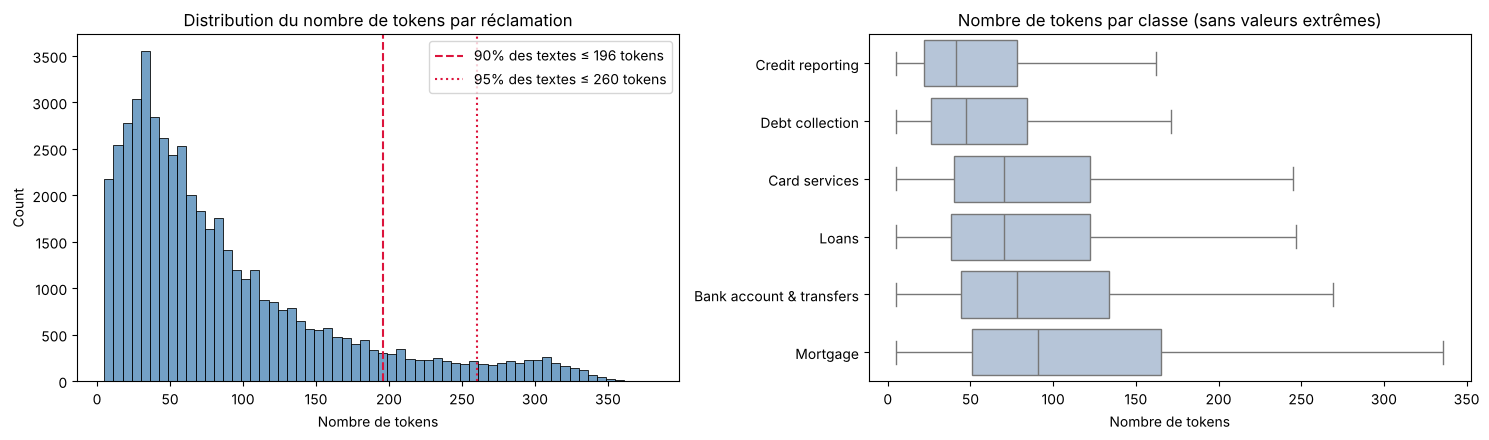

In [10]:
# Distribution des longueurs après nettoyage, globalement et par classe, pour choisir `maxlen`.
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.histplot(df["n_tokens"], bins=60, ax=axes[0], color="steelblue")
for q, style in [(0.90, "--"), (0.95, ":")]:
    v = df["n_tokens"].quantile(q)
    axes[0].axvline(v, color="crimson", linestyle=style, label=f"{q:.0%} des textes ≤ {v:.0f} tokens")
axes[0].set_title("Distribution du nombre de tokens par réclamation")
axes[0].set_xlabel("Nombre de tokens")
axes[0].legend()

order = df.groupby("label")["n_tokens"].median().sort_values().index
sns.boxplot(data=df, y="label", x="n_tokens", order=order, showfliers=False, ax=axes[1], color="lightsteelblue")
axes[1].set_title("Nombre de tokens par classe (sans valeurs extrêmes)")
axes[1].set_xlabel("Nombre de tokens")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Interprétation.** Le nettoyage complémentaire ne retire qu'environ 1 % des données et ne modifie pas
l'équilibre des classes. Les longueurs diffèrent selon la classe : les réclamations *Mortgage* sont les plus
longues (médiane ≈ 90 tokens), *Credit reporting* et *Debt collection* les plus courtes (≈ 40-45 tokens). La
longueur est donc un indice, mais les distributions se chevauchent largement : le modèle devra s'appuyer sur le
contenu. Les 10 000 mots les plus fréquents couvrant ≈ 99 % des occurrences, `num_words=10000` suffira. Un `maxlen` d'environ **200 tokens** (≈ 90 % des
textes entiers) est un bon compromis entre information conservée et coût d'entraînement d'un RNN (le temps de
calcul croît avec la longueur de séquence) ; cette valeur fera partie des hyperparamètres testés.

## 4. Découpage train / test

In [11]:
# Découpage stratifié : chaque classe garde la même proportion dans le train et dans le test.
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=TEST_SIZE, stratify=df["label"], random_state=RANDOM_STATE)

# Contrôle de fuite : aucun texte du test ne doit apparaître dans le train.
overlap = set(X_train) & set(X_test)
assert not overlap, f"{len(overlap)} textes communs entre train et test"
print(f"Train : {len(X_train):,} | Test : {len(X_test):,} | Textes communs : {len(overlap)}")

pd.DataFrame({"train %": y_train.value_counts(normalize=True).round(3),
              "test %": y_test.value_counts(normalize=True).round(3)})

Train : 39,571 | Test : 9,893 | Textes communs : 0


,train %,test %
label,,
Debt collection,0.261,0.261
Mortgage,0.229,0.229
Credit reporting,0.176,0.176
Card services,0.135,0.135
Loans,0.100,0.100
Bank account & transfers,0.099,0.099


**Interprétation.** Les proportions des classes sont identiques dans le train et le test grâce à la
stratification, et aucun texte n'est partagé entre les deux ensembles : l'évaluation du futur RNN sera fiable.
Le jeu de données est **propre et prêt** pour l'étape suivante : tokenisation Keras (`Tokenizer` limité aux mots
les plus fréquents + token `<OOV>`, ajusté **uniquement sur le train**), padding des séquences à `maxlen`, puis
encodage des étiquettes.

## 5. Tokenisation
Un RNN ne lit pas du texte mais des **séquences d'entiers**. La tokenisation consiste à :
1. construire un **vocabulaire** (mot → indice entier), classé par fréquence décroissante ;
2. remplacer chaque mot d'un texte par son indice.

Choix effectués :
- on utilise le `Tokenizer` de TensorFlow (`tf.keras.preprocessing.text.Tokenizer`), comme dans le TP 3.2 ;
- le vocabulaire est **limité aux `VOCAB_SIZE` mots les plus fréquents** (cf. section 2.4 : 10 000 mots couvrent
  ≈ 99 % des occurrences) ; tous les autres mots sont remplacés par un token spécial `<OOV>` (*out of vocabulary*)
  au lieu d'être supprimés, ce qui conserve la longueur et la position des mots dans la séquence ;
- le tokenizer est ajusté **uniquement sur le train** : le vocabulaire ne doit rien « savoir » du jeu de test,
  sinon on introduirait une fuite d'information.

In [12]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # masque les messages techniques de TensorFlow (doit précéder l'import)
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder

tf.random.set_seed(RANDOM_STATE)   # reproductibilité côté TensorFlow
np.random.seed(RANDOM_STATE)
print("TensorFlow :", tf.__version__)

VOCAB_SIZE = 10_000   # hyperparamètre : taille du vocabulaire conservé (indices 1 à VOCAB_SIZE - 1)
OOV_TOKEN = "<OOV>"   # token de remplacement des mots hors vocabulaire

# Les textes sont déjà en minuscules et sans ponctuation : les filtres par défaut du Tokenizer ne changent rien,
# le découpage se fait sur les espaces.
tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(X_train)   # vocabulaire appris sur le train uniquement

# Conversion texte -> liste d'entiers (les mots hors des VOCAB_SIZE premiers deviennent l'indice de <OOV>)
seq_train = tokenizer.texts_to_sequences(X_train)
seq_test = tokenizer.texts_to_sequences(X_test)

print(f"Mots distincts vus dans le train : {len(tokenizer.word_index):,}")
print(f"Mots conservés dans le vocabulaire : {VOCAB_SIZE - 1:,} (indice 0 réservé au padding)")
print("Indice du token OOV :", tokenizer.word_index[OOV_TOKEN])
print("10 premiers indices :", list(tokenizer.word_index.items())[:10])

I0000 00:00:1791798938.693415    1019 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791798941.491433    1019 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow : 2.21.0


Mots distincts vus dans le train : 36,665
Mots conservés dans le vocabulaire : 9,999 (indice 0 réservé au padding)
Indice du token OOV : 1
10 premiers indices : [('<OOV>', 1), ('not', 2), ('credit', 3), ('account', 4), ('payment', 5), ('loan', 6), ('would', 7), ('bank', 8), ('time', 9), ('no', 10)]


In [13]:
# Exemple : un texte court du train contenant un mot rare, sa séquence d'entiers et la séquence décodée
# (mot retrouvé pour chaque indice) : le mot rare est remplacé par l'indice 1 = <OOV>.
oov_id = tokenizer.word_index[OOV_TOKEN]
i = next(k for k, s in enumerate(seq_train) if oov_id in s and len(s) <= 30)
seq = seq_train[i]
print("TEXTE    :", X_train.iloc[i], "\n")
print("SÉQUENCE :", seq, "\n")
print("DÉCODÉ   :", " ".join(tokenizer.index_word[idx] for idx in seq))
print(f"\nLongueur : {len(X_train.iloc[i].split())} mots -> {len(seq)} entiers")

TEXTE    : last statement cycle payment full mailed usps anddue yet payment case held thus incurring late fee american express common thievery know fewoptions please use caution dealing amx ethic not featured 

SÉQUENCE : [87, 62, 1258, 5, 104, 401, 1648, 1, 189, 5, 109, 583, 834, 3068, 55, 37, 438, 555, 1745, 7956, 65, 1, 80, 233, 6866, 886, 7078, 3417, 2, 7325] 

DÉCODÉ   : last statement cycle payment full mailed usps <OOV> yet payment case held thus incurring late fee american express common thievery know <OOV> please use caution dealing amx ethic not featured

Longueur : 30 mots -> 30 entiers


In [14]:
# Proportion de tokens remplacés par <OOV> : mesure la perte d'information due à la limite VOCAB_SIZE.

def oov_stats(sequences):
    flat = np.concatenate([np.array(s) for s in sequences])
    textes_oov = np.mean([oov_id in s for s in sequences])
    return (flat == oov_id).mean(), textes_oov

for nom, seqs in [("train", seq_train), ("test", seq_test)]:
    taux, textes = oov_stats(seqs)
    print(f"{nom:5s} : {taux:.2%} des tokens sont <OOV> | {textes:.0%} des textes contiennent au moins un <OOV>")

train : 1.24% des tokens sont <OOV> | 42% des textes contiennent au moins un <OOV>
test  : 1.44% des tokens sont <OOV> | 45% des textes contiennent au moins un <OOV>


**Interprétation.** Le train contient ≈ 36 700 mots distincts, dont seuls les 9 999 plus fréquents reçoivent un
indice propre ; l'indice 1 est réservé à `<OOV>` et l'ordre des indices reflète la fréquence (`not`, `credit`,
`account`, `payment`, `loan`…). L'exemple montre que la conversion est **réversible** pour les mots connus et que
les mots rares sont remplacés par `<OOV>` sans changer la longueur du texte. Seulement **≈ 1,2 % des tokens du
train** deviennent `<OOV>` : la limitation du vocabulaire fait perdre très peu d'information tout en divisant par
près de 4 la taille de la future matrice d'embedding. Le taux est à peine plus élevé sur le test (≈ 1,4 %), ce qui
est attendu puisque le vocabulaire n'a pas vu ces textes : l'écart est faible, le vocabulaire **généralise bien**.
Près de la moitié des textes contiennent au moins un `<OOV>` (noms propres, fautes de frappe), mais seulement
2 mots `<OOV>` en médiane dans ces textes.

## 6. Padding

Un réseau de neurones traite les données par **lots (batchs) de tenseurs de taille fixe**, alors que les
réclamations ont des longueurs très variables (de 5 à 380 tokens). Le **padding** ramène toutes les séquences à
la même longueur `MAX_LEN` :
- les séquences plus **courtes** sont complétées avec des **0** (indice réservé, qui ne correspond à aucun mot) ;
- les séquences plus **longues** sont **tronquées**.

Choix effectués :
- `MAX_LEN = 200` : ≈ 90 % des textes sont conservés en entier (cf. section 3), sans payer le coût de calcul des
  quelques textes très longs (le temps d'entraînement d'un RNN croît avec la longueur de la séquence) ;
- `padding="pre"` (zéros **au début**) : un LSTM résume la séquence dans son **dernier état caché** ; avec des
  zéros à la fin, ce dernier état serait calculé après une longue suite de zéros et « oublierait » une partie du
  texte. Les zéros en tête évitent ce problème (on pourra aussi tester `padding="post"` avec `mask_zero=True`
  dans la couche `Embedding`) ;
- `truncating="post"` (on coupe **la fin**) : le client présente généralement son produit et son problème dès les
  premières phrases ; la fin contient plutôt les demandes et les formules de politesse.

`MAX_LEN` et ces deux options font partie des hyperparamètres à expérimenter (longueur de séquence / fenêtre
d'entrée dans le tableau de la consigne).

In [15]:
MAX_LEN = 200   # hyperparamètre : longueur de séquence vue par le RNN

pad = lambda seqs: tf.keras.utils.pad_sequences(seqs, maxlen=MAX_LEN, padding="pre", truncating="post")
X_train_pad = pad(seq_train)
X_test_pad = pad(seq_test)

len_train = np.array([len(s) for s in seq_train])
print(f"Forme X_train_pad : {X_train_pad.shape} | X_test_pad : {X_test_pad.shape} | type : {X_train_pad.dtype}")
print(f"Textes tronqués (train)        : {(len_train > MAX_LEN).mean():.1%}")
print(f"Tokens perdus par troncature   : {np.clip(len_train - MAX_LEN, 0, None).sum() / len_train.sum():.1%}")
print(f"Part de zéros (padding, train) : {(X_train_pad == 0).mean():.1%}")

# Exemple de séquence courte après padding : les zéros sont ajoutés au début
j = int(np.argmin(len_train))
print(f"\nSéquence la plus courte ({len_train[j]} tokens) après padding (30 dernières positions) :")
print(X_train_pad[j][-30:])

Forme X_train_pad : (39571, 200) | X_test_pad : (9893, 200) | type : int32
Textes tronqués (train)        : 9.5%
Tokens perdus par troncature   : 7.3%
Part de zéros (padding, train) : 60.0%

Séquence la plus courte (5 tokens) après padding (30 dernières positions) :
[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0 295  53 700  53 700]


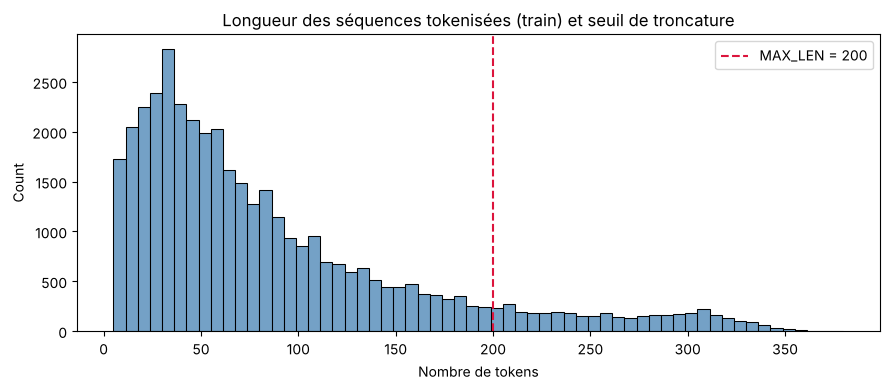

In [16]:
# Visualisation : longueur des séquences tokenisées et seuil MAX_LEN
plt.figure(figsize=(9, 4))
sns.histplot(len_train, bins=60, color="steelblue")
plt.axvline(MAX_LEN, color="crimson", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.title("Longueur des séquences tokenisées (train) et seuil de troncature")
plt.xlabel("Nombre de tokens")
plt.legend()
plt.tight_layout()
plt.show()

**Interprétation.** Les deux ensembles sont maintenant des matrices d'entiers de forme *(nombre de textes, 200)*.
Avec `MAX_LEN = 200`, **≈ 9,5 % des textes sont tronqués** mais on ne perd que **≈ 7 % des tokens** du corpus :
seuls les textes très longs sont raccourcis, et ils gardent leurs 200 premiers mots. En contrepartie, la
majorité des réclamations sont courtes (médiane ≈ 60 tokens) et **≈ 60 % des positions sont des zéros de
padding** : c'est un coût de calcul pour le RNN, et la raison du choix `padding="pre"` (les vrais mots sont
traités en dernier, juste avant la prédiction). Réduire `MAX_LEN` (ex. 120) accélérerait l'entraînement mais
tronquerait davantage de textes : ce compromis sera testé lors de l'optimisation des hyperparamètres.

## 7. Encodage des étiquettes

In [17]:
# Les 6 classes textuelles sont converties en entiers 0..5. Le modèle aura une couche de sortie softmax à
# 6 neurones et la perte `sparse_categorical_crossentropy`, qui accepte directement des étiquettes entières
# (pas besoin d'encodage one-hot).
label_encoder = LabelEncoder()
y_train_enc = label_encoder.fit_transform(y_train)   # ajusté sur le train
y_test_enc = label_encoder.transform(y_test)
CLASSES = list(label_encoder.classes_)
NUM_CLASSES = len(CLASSES)

print("Correspondance indice -> classe :")
for k, c in enumerate(CLASSES):
    print(f"  {k} : {c}")
print(f"\ny_train_enc : {y_train_enc.shape} | y_test_enc : {y_test_enc.shape} | exemples : {y_train_enc[:10]}")

Correspondance indice -> classe :
  0 : Bank account & transfers
  1 : Card services
  2 : Credit reporting
  3 : Debt collection
  4 : Loans
  5 : Mortgage

y_train_enc : (39571,) | y_test_enc : (9893,) | exemples : [2 5 2 3 1 5 5 0 1 0]


In [18]:
# Récapitulatif des tenseurs prêts pour le modèle
pd.DataFrame({
    "forme": [X_train_pad.shape, X_test_pad.shape, y_train_enc.shape, y_test_enc.shape],
    "min": [X_train_pad.min(), X_test_pad.min(), y_train_enc.min(), y_test_enc.min()],
    "max": [X_train_pad.max(), X_test_pad.max(), y_train_enc.max(), y_test_enc.max()],
}, index=["X_train_pad", "X_test_pad", "y_train_enc", "y_test_enc"])

,forme,min,max
X_train_pad,"(39571, 200)",0,9999
X_test_pad,"(9893, 200)",0,9999
y_train_enc,"(39571,)",0,5
y_test_enc,"(9893,)",0,5


**Interprétation.** Les étiquettes sont des entiers de 0 à 5 dans l'ordre alphabétique des classes ; le
`LabelEncoder` est conservé pour retraduire les prédictions en noms de services. Les entrées vont de 0 (padding)
à 9 999 (dernier mot du vocabulaire) : la couche `Embedding` du modèle aura donc `input_dim = VOCAB_SIZE`
(10 000) et `input_length = MAX_LEN` (200), et la couche de sortie `NUM_CLASSES` (6) neurones avec un softmax.
Comme indiqué dans la consigne, **aucune mise à l'échelle** (MinMax, standardisation) n'est appliquée : les
indices ne sont pas des grandeurs numériques mais des identifiants, que la couche `Embedding` transformera en
vecteurs denses appris pendant l'entraînement. Les données sont prêtes pour la conception du RNN.

## 8. Conception du modèle RNN

### 8.1 Pourquoi un RNN, et pourquoi un LSTM ?
Le modèle TF-IDF du TP 2.3 traitait chaque texte comme un **sac de mots** : l'ordre était perdu
(« *not* paid » et « paid, *not* late » donnaient des représentations proches). Un **réseau récurrent** lit la
séquence **mot par mot**, en mettant à jour un **état caché** qui résume ce qu'il a lu jusque-là : il peut donc
exploiter le contexte et l'ordre des mots.

Un RNN simple (`SimpleRNN`) souffre cependant du **problème de disparition du gradient** : sur des séquences de
200 pas de temps comme les nôtres, l'information des premiers mots s'efface avant la fin. Le **LSTM** (*Long
Short-Term Memory*) ajoute une **cellule mémoire** contrôlée par trois portes (oubli, entrée, sortie) qui
décident quoi garder, ajouter ou restituer : il retient l'information sur de longues séquences. C'est donc le
**LSTM** que nous retenons comme modèle principal ; le `SimpleRNN` servira de point de comparaison.

### 8.2 Architecture retenue

| # | Couche | Rôle | Sortie (par texte) |
|---|---|---|---|
| 1 | `Input` | séquence de `MAX_LEN` = 200 indices de mots | (200,) |
| 2 | `Embedding(10 000, 128)` | transforme chaque indice en un **vecteur dense** de 128 dimensions, appris pendant l'entraînement : les mots de sens proche (« mortgage », « escrow ») finissent proches dans cet espace | (200, 128) |
| 3 | `LSTM(64)` | lit les 200 vecteurs dans l'ordre et résume tout le texte dans son **dernier état caché** (`return_sequences=False`) | (64,) |
| 4 | `Dropout(0.3)` | désactive aléatoirement 30 % des neurones pendant l'entraînement pour limiter le **sur-apprentissage** | (64,) |
| 5 | `Dense(64, relu)` | combine les caractéristiques extraites par le LSTM | (64,) |
| 6 | `Dropout(0.3)` | régularisation | (64,) |
| 7 | `Dense(6, softmax)` | une **probabilité par classe** (somme = 1) ; la classe prédite est la plus probable | (6,) |

**Compilation :**
- optimiseur **Adam** (taux d'apprentissage adaptatif, valeur par défaut 1e-3) ;
- perte **`sparse_categorical_crossentropy`** : classification multi-classes avec étiquettes entières (section 7).
  On n'utilise pas `binary_crossentropy` comme au TP 3.2 car il y a 6 classes et non 2 ;
- métrique suivie pendant l'entraînement : **accuracy** (le F1 macro sera calculé à l'évaluation, car les classes
  sont déséquilibrées).

Pour pouvoir **expérimenter facilement** (partie 5 de la consigne), le modèle est construit par une fonction
`build_model` dont chaque hyperparamètre du tableau de la consigne est un argument : type de cellule
(`SimpleRNN` / `LSTM` / `GRU`), nombre d'unités, nombre de couches, taux de dropout, taux d'apprentissage,
et en option un LSTM **bidirectionnel**.

In [19]:
from tensorflow.keras import layers, models, optimizers

EMBED_DIM = 128   # dimension des vecteurs de mots

RNN_LAYERS = {"SimpleRNN": layers.SimpleRNN, "LSTM": layers.LSTM, "GRU": layers.GRU}


def build_model(rnn_type="LSTM", units=64, n_layers=1, dropout=0.3, learning_rate=1e-3,
                bidirectional=False, embed_dim=EMBED_DIM, max_len=MAX_LEN, vocab_size=VOCAB_SIZE,
                dense_units=64, name=None):
    """Construit et compile un classifieur récurrent de textes.

    rnn_type      : "SimpleRNN", "LSTM" ou "GRU"
    units         : nombre de neurones (taille de l'état caché) de chaque couche récurrente
    n_layers      : nombre de couches récurrentes empilées
    dropout       : fraction de neurones désactivés après chaque couche (régularisation)
    learning_rate : taux d'apprentissage de l'optimiseur Adam
    bidirectional : si True, chaque couche lit la séquence dans les deux sens
    """
    model = models.Sequential(name=name or f"{rnn_type}_{n_layers}x{units}")
    model.add(layers.Input(shape=(max_len,), dtype="int32"))
    # Indices de mots -> vecteurs denses appris. Pas de mise à l'échelle nécessaire en amont.
    model.add(layers.Embedding(input_dim=vocab_size, output_dim=embed_dim))

    for k in range(n_layers):
        # Les couches intermédiaires doivent renvoyer TOUTE la séquence d'états cachés (return_sequences=True)
        # pour alimenter la couche récurrente suivante ; la dernière ne renvoie que l'état final (résumé du texte).
        last = (k == n_layers - 1)
        rnn = RNN_LAYERS[rnn_type](units, return_sequences=not last)
        model.add(layers.Bidirectional(rnn) if bidirectional else rnn)
        model.add(layers.Dropout(dropout))

    model.add(layers.Dense(dense_units, activation="relu"))
    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(NUM_CLASSES, activation="softmax"))   # une probabilité par classe

    model.compile(optimizer=optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

### 8.3 Modèle principal : LSTM à une couche

In [20]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RANDOM_STATE)   # graines Python, NumPy et TensorFlow

lstm_model = build_model(rnn_type="LSTM", units=64, n_layers=1, dropout=0.3, learning_rate=1e-3)
lstm_model.summary()

Model: "LSTM_1x64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,333,958 (5.09 MB)

 Trainable params: 1,333,958 (5.09 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Répartition des paramètres entraînables par couche : où se trouve la « capacité » du modèle ?
params = pd.DataFrame(
    [(l.name, l.__class__.__name__, l.count_params()) for l in lstm_model.layers],
    columns=["couche", "type", "paramètres"])
params["%"] = (params["paramètres"] / params["paramètres"].sum() * 100).round(1)

# Vérification du calcul pour le LSTM : 4 portes x (units x (entrée + units) + biais)
units = 64
print("Paramètres LSTM attendus :", 4 * (units * (EMBED_DIM + units) + units))
params

Paramètres LSTM attendus : 49408


,couche,type,paramètres,%
0,embedding,Embedding,1280000,96.0
1,lstm,LSTM,49408,3.7
2,dropout,Dropout,0,0.0
3,dense,Dense,4160,0.3
4,dropout_1,Dropout,0,0.0
5,dense_1,Dense,390,0.0


**Interprétation.** Le modèle compte ≈ **1,33 million de paramètres**, dont **96 % dans la couche `Embedding`**
(10 000 mots × 128 dimensions) : l'essentiel de l'apprentissage consistera à construire une bonne représentation
des mots. Le LSTM n'en a que 49 408, ce qui correspond exactement à la formule 4 × (64 × (128 + 64) + 64) : les
4 blocs de poids sont la porte d'oubli, la porte d'entrée, la porte de sortie et la cellule candidate, chacun
recevant l'entrée (128) et l'état caché précédent (64). Les couches `Dropout` n'ont aucun paramètre : elles
n'agissent que pendant l'entraînement. Avec ≈ 40 000 textes d'entraînement pour 1,3 M de paramètres, le risque de
**sur-apprentissage** est réel, ce qui justifie le dropout et le suivi d'un jeu de validation.

### 8.4 Vérifications avant entraînement
Avant de lancer un entraînement long, on vérifie que le modèle est correctement branché :
1. il accepte nos données (`X_train_pad`) et renvoie bien **6 probabilités par texte, de somme 1** ;
2. sa **perte initiale** est proche de la valeur théorique d'un modèle qui répond au hasard : avec des poids
   aléatoires, il attribue ≈ 1/6 à chaque classe, donc la perte d'entropie croisée vaut ≈ ln(6) ≈ 1,79.
   Une valeur très différente signalerait un problème (étiquettes mal encodées, mauvaise fonction de perte…).

In [22]:
batch = X_train_pad[:256]
proba = lstm_model.predict(batch, verbose=0)
print("Forme de la sortie :", proba.shape)
print("Somme des probabilités (min / max) :", proba.sum(axis=1).min().round(4), "/", proba.sum(axis=1).max().round(4))
print("Probabilités du 1er texte :", proba[0].round(3))

loss0, acc0 = lstm_model.evaluate(batch, y_train_enc[:256], verbose=0)
print(f"\nPerte initiale : {loss0:.3f} (théorique au hasard : ln(6) = {np.log(NUM_CLASSES):.3f})")
print(f"Accuracy initiale : {acc0:.3f} (hasard ≈ {1 / NUM_CLASSES:.3f}, classe majoritaire = 0.261)")

Forme de la sortie : (256, 6)
Somme des probabilités (min / max) : 1.0 / 1.0
Probabilités du 1er texte : [0.166 0.165 0.166 0.168 0.168 0.167]



Perte initiale : 1.791 (théorique au hasard : ln(6) = 1.792)
Accuracy initiale : 0.176 (hasard ≈ 0.167, classe majoritaire = 0.261)


**Interprétation.** Le modèle est correctement branché : il prend des lots de séquences de 200 entiers et
renvoie 6 probabilités de somme 1. Avant entraînement, ces probabilités sont toutes ≈ 1/6 (entre 0,16 et 0,18) et la
**perte initiale (1,791) correspond exactement à ln(6) = 1,792** : le modèle part bien d'une prédiction « au
hasard », sans biais vers une classe, et les étiquettes sont dans le format attendu par la perte. L'accuracy
initiale est logiquement proche du hasard (0,167), à quelques points près selon l'initialisation aléatoire des poids : tout ce qui sera gagné au-delà, et surtout au-delà de
la classe majoritaire (0,261), viendra de l'apprentissage.

### 8.5 Variantes prévues pour les expériences
La même fonction permet de construire les variantes à comparer : un `SimpleRNN` (référence « RNN de base »),
un LSTM empilé à 2 couches, un LSTM bidirectionnel et un GRU. Le tableau ci-dessous compare leur taille.

In [23]:
variantes = {
    "SimpleRNN 1x64": dict(rnn_type="SimpleRNN"),
    "LSTM 1x64 (principal)": dict(rnn_type="LSTM"),
    "LSTM 2x64 (empilé)": dict(rnn_type="LSTM", n_layers=2),
    "BiLSTM 1x64": dict(rnn_type="LSTM", bidirectional=True),
    "GRU 1x64": dict(rnn_type="GRU"),
}
rows = []
for nom, cfg in variantes.items():
    m = build_model(**cfg)
    total = m.count_params()
    emb = m.layers[0].count_params()
    rows.append({"variante": nom, "paramètres totaux": total, "dont Embedding": emb,
                 "dont couches récurrentes + Dense": total - emb})
pd.DataFrame(rows).set_index("variante")

,paramètres totaux,dont Embedding,dont couches récurrentes + Dense
variante,,,
SimpleRNN 1x64,1296902,1280000,16902
LSTM 1x64 (principal),1333958,1280000,53958
LSTM 2x64 (empilé),1366982,1280000,86982
BiLSTM 1x64,1387462,1280000,107462
GRU 1x64,1321798,1280000,41798


**Interprétation.** Toutes les variantes partagent la même couche `Embedding` (1,28 M paramètres) ; elles ne
diffèrent que par la partie récurrente :
- le **SimpleRNN** est le plus léger (≈ 17 k paramètres hors embedding) : une seule transformation par pas de
  temps, sans porte, d'où sa difficulté attendue à retenir l'information sur 200 mots ;
- le **GRU** (2 portes) est un intermédiaire entre SimpleRNN et LSTM (≈ 42 k) ;
- le **LSTM** (3 portes + cellule mémoire) a ≈ 4× plus de paramètres récurrents que le SimpleRNN ;
- **empiler** une 2e couche LSTM (+ 33 k) ou rendre le LSTM **bidirectionnel** (×2 sur la partie récurrente)
  augmente la capacité du modèle, mais aussi le temps d'entraînement et le risque de sur-apprentissage.

Ces écarts de taille restent faibles devant l'embedding : la différence de performance entre variantes viendra
surtout de leur **façon de traiter la séquence** (portes, mémoire, lecture dans les deux sens) plutôt que de leur
nombre de paramètres. Le modèle est conçu et vérifié ; l'étape suivante est son **entraînement** sur
`X_train_pad` / `y_train_enc`, avec un jeu de validation pour surveiller le sur-apprentissage.

## 9. Entraînement du modèle

### 9.1 Protocole
- **Jeu de validation** : 10 % du train (stratifié) est mis de côté. Il sert à suivre la généralisation pendant
  l'entraînement, à arrêter l'apprentissage au bon moment et, en section 11, à **comparer les variantes**.
  Le **jeu de test n'est utilisé qu'à la toute fin** pour mesurer la performance des modèles retenus : s'en servir
  pour choisir les hyperparamètres reviendrait à « tricher » et surestimerait les scores.
- **Arrêt anticipé (`EarlyStopping`)** : on surveille la perte de validation ; si elle ne s'améliore plus pendant
  `PATIENCE` epochs, l'entraînement s'arrête et l'on **restaure les poids de la meilleure epoch**. Cela évite le
  sur-apprentissage sans avoir à deviner le bon nombre d'epochs.
- **Taille de batch** : 64 textes par mise à jour des poids (compromis entre stabilité du gradient et vitesse).

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
import time

EPOCHS = 15       # nombre maximal d'epochs (l'arrêt anticipé s'arrête généralement avant)
BATCH_SIZE = 64
PATIENCE = 2      # epochs sans amélioration de val_loss tolérées avant l'arrêt

# Découpage train / validation par indices : on pourra ainsi re-padder les mêmes textes avec un autre MAX_LEN
# (expériences de la section 11) en gardant exactement la même répartition.
idx_tr, idx_val = train_test_split(np.arange(len(y_train_enc)), test_size=0.1,
                                   stratify=y_train_enc, random_state=RANDOM_STATE)
X_tr, X_val = X_train_pad[idx_tr], X_train_pad[idx_val]
y_tr, y_val = y_train_enc[idx_tr], y_train_enc[idx_val]
print(f"Entraînement : {len(y_tr):,} | Validation : {len(y_val):,} | Test (mis de côté) : {len(y_test_enc):,}")


def early_stopping():
    return tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)

In [ ]:
# Entraînement du modèle principal conçu en section 8 (LSTM 1 x 64).
tf.keras.utils.set_random_seed(RANDOM_STATE)
lstm_model = build_model(rnn_type="LSTM", units=64, n_layers=1, dropout=0.3, learning_rate=1e-3, name="LSTM_principal")

t0 = time.time()
history = lstm_model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                         epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=[early_stopping()], verbose=2)
train_time = time.time() - t0
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"\nDurée d'entraînement : {train_time / 60:.1f} min | epochs effectuées : {len(history.history['loss'])} "
      f"| meilleure epoch (poids restaurés) : {best_epoch}")

In [ ]:
# Courbes d'apprentissage : perte et accuracy sur l'entraînement et la validation à chaque epoch.
def plot_history(history, title=""):
    h = pd.DataFrame(history.history)
    h.index = h.index + 1
    best = int(h["val_loss"].idxmin())
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    for ax, metric, label in [(axes[0], "loss", "Perte (entropie croisée)"), (axes[1], "accuracy", "Accuracy")]:
        ax.plot(h.index, h[metric], "o-", label="entraînement")
        ax.plot(h.index, h[f"val_{metric}"], "o-", label="validation")
        ax.axvline(best, color="grey", linestyle="--", label=f"meilleure epoch ({best})")
        ax.set_title(f"{label} {title}")
        ax.set_xlabel("Epoch")
        ax.legend()
    plt.tight_layout()
    plt.show()
    return h

plot_history(history, "– LSTM principal").round(4)

**Interprétation.** *(valeurs indicatives observées lors de nos essais, ±1 point selon la machine)*
- **Epoch 1** : la perte chute fortement (≈ 1,05 en entraînement), et l'accuracy de validation atteint déjà
  ≈ 0,73. L'embedding et le LSTM apprennent très vite les mots les plus discriminants (« mortgage »,
  « debt », « card »…).
- **Epochs 2 à 5** : la validation progresse plus lentement, jusqu'à ≈ 0,83. Elle peut connaître une ou deux
  epochs moins bonnes : l'optimisation d'un LSTM sur des séquences de 200 pas est un peu instable.
- **Ensuite**, la perte d'entraînement continue de baisser mais **la perte de validation remonte** : le modèle
  commence à **sur-apprendre**, c'est-à-dire à mémoriser le train. L'écart entre les deux courbes se creuse.
  L'arrêt anticipé stoppe l'entraînement après `PATIENCE` epochs sans amélioration et **restaure les poids de la
  meilleure epoch** (≈ 5ᵉ epoch, environ 4 à 6 minutes d'entraînement sur CPU).

Malgré le dropout, le modèle (1,3 M de paramètres) sur-apprend rapidement : c'est l'un des axes testés en
section 11 (dropout, nombre d'unités).

## 10. Évaluation sur le jeu de test

On mesure la performance sur les **9 893 réclamations du test**, jamais vues pendant l'entraînement :
- **accuracy** : part de réclamations envoyées au bon service ;
- **précision** (par classe) : parmi les réclamations envoyées à un service, part qui lui était bien destinée ;
- **rappel** (par classe) : parmi les réclamations d'un service, part qui lui a bien été envoyée ;
- **F1** : moyenne harmonique précision / rappel. La moyenne **macro** donne le même poids aux 6 classes : c'est
  l'indicateur principal, car les classes sont déséquilibrées (une accuracy élevée pourrait masquer un mauvais
  traitement des petites classes).

In [ ]:
def evaluate(model, X, y):
    # Renvoie les métriques globales et les prédictions (classe la plus probable) d'un modèle.
    proba = model.predict(X, verbose=0)
    pred = proba.argmax(axis=1)
    scores = {
        "accuracy": accuracy_score(y, pred),
        "précision macro": precision_score(y, pred, average="macro"),
        "rappel macro": recall_score(y, pred, average="macro"),
        "F1 macro": f1_score(y, pred, average="macro"),
        "F1 pondéré": f1_score(y, pred, average="weighted"),
    }
    return scores, pred, proba

scores_lstm, y_pred, y_proba = evaluate(lstm_model, X_test_pad, y_test_enc)
print("LSTM principal – jeu de test")
for k, v in scores_lstm.items():
    print(f"  {k:16s}: {v:.3f}")

print("\nRapport détaillé par classe :")
print(classification_report(y_test_enc, y_pred, target_names=CLASSES, digits=3))

**Interprétation.** Le LSTM atteint une **accuracy d'environ 0,84 et un F1 macro d'environ 0,82** sur le
test : environ 84 réclamations sur 100 sont routées vers le bon service, contre 26 sur 100 pour un modèle qui
répondrait toujours la classe majoritaire. Les scores varient selon les classes :
- **les mieux reconnues** : *Mortgage* et *Credit reporting* (F1 ≈ 0,9). Leur vocabulaire est très spécifique
  (« escrow », « foreclosure », « modification » / « equifax », « inquiry », « dispute »), et ce sont des
  classes bien représentées ;
- **les plus difficiles** : *Loans* et *Bank account & transfers*. Ce sont les deux plus petites classes
  (≈ 10 % chacune), elles regroupent plusieurs produits hétérogènes (prêts étudiants, auto, payday ; comptes,
  virements, autres services) et partagent du vocabulaire avec les autres classes (« payment », « account »).

La précision et le rappel macro sont proches : le modèle n'est pas systématiquement biaisé vers les grandes
classes.

In [ ]:
# Matrices de confusion : en effectifs et en pourcentage de chaque vraie classe (= rappel sur la diagonale).
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (titre, norm, fmt) in zip(axes, [("effectifs", None, "d"), ("% de la vraie classe", "true", ".1%")]):
    ConfusionMatrixDisplay.from_predictions(y_test_enc, y_pred, display_labels=CLASSES, normalize=norm,
                                            values_format=fmt, cmap="Blues", ax=ax, colorbar=False,
                                            xticks_rotation=35)
    ax.set_title(f"Matrice de confusion – LSTM – {titre}")
plt.tight_layout()
plt.show()

cm = pd.DataFrame(confusion_matrix(y_test_enc, y_pred, normalize="true"), index=CLASSES, columns=CLASSES)
top = cm.where(~np.eye(NUM_CLASSES, dtype=bool)).stack().sort_values(ascending=False).head(4)
print("Confusions les plus fréquentes (vraie classe → classe prédite : % de la vraie classe) :")
for (vrai, pred), v in top.items():
    print(f"  {vrai} → {pred} : {v:.1%}")

**Interprétation.** La diagonale (rappel par classe) est nettement dominante. Les erreurs ne sont pas
aléatoires : elles se concentrent entre classes **métier voisines**, déjà identifiées au TP 2.3 :
- **Credit reporting ↔ Debt collection** : une dette en recouvrement apparaît sur le rapport de crédit, et le
  client parle souvent des deux (« collection account on my credit report ») ;
- **Loans → Debt collection** : un prêt impayé est transmis à une agence de recouvrement ;
- **Bank account & transfers ↔ Card services** : comptes, cartes de débit et litiges de paiement se recoupent.

Ces confusions reflètent en partie un **bruit d'étiquetage** : c'est le client qui choisit le produit dans le
formulaire du CFPB, et beaucoup de réclamations concernent réellement plusieurs services. Un routage
automatique pourrait proposer les **deux services les plus probables** dans ces cas ambigus.

In [ ]:
# Analyse d'erreurs : quelques réclamations mal classées avec la confiance du modèle.
test_df = pd.DataFrame({"texte": X_test.values, "vrai": y_test.values,
                        "prédit": label_encoder.inverse_transform(y_pred), "confiance": y_proba.max(axis=1)})
erreurs = test_df[test_df["vrai"] != test_df["prédit"]]
print(f"Réclamations mal classées : {len(erreurs):,} / {len(test_df):,}")
print(f"Confiance moyenne : {test_df.loc[test_df['vrai'] == test_df['prédit'], 'confiance'].mean():.2f} "
      f"(bonnes prédictions) vs {erreurs['confiance'].mean():.2f} (erreurs)\n")
for _, r in erreurs.sample(4, random_state=RANDOM_STATE).iterrows():
    print(f"[vrai : {r['vrai']} | prédit : {r['prédit']} ({r['confiance']:.0%})]\n  {r['texte'][:300]}\n")

**Interprétation.** Le modèle est **nettement moins confiant sur ses erreurs** que sur ses bonnes
prédictions : sa probabilité maximale est donc un bon indicateur de fiabilité. En pratique, on pourrait router
automatiquement les réclamations dont la confiance dépasse un seuil, et envoyer les autres à un opérateur
humain. Les exemples d'erreurs montrent surtout des réclamations **ambiguës**, qui évoquent plusieurs produits
ou dont l'étiquette choisie par le client est discutable. Il y a aussi des textes où l'information décisive
apparaît **après les 200 premiers tokens** (troncature) ou dans des mots devenus `<OOV>`.

In [ ]:
# Comparaison avec des références :
# - classe majoritaire : modèle « naïf » qui prédit toujours Debt collection ;
# - meilleur modèle du TP 2.3 (SVM linéaire sur TF-IDF, même corpus et même proportion de test, scores repris du TP 2.3).
majo = np.full_like(y_test_enc, np.bincount(y_tr).argmax())
comparaison = pd.DataFrame({
    "Classe majoritaire": {"accuracy": accuracy_score(y_test_enc, majo), "F1 macro": f1_score(y_test_enc, majo, average="macro")},
    "SVM linéaire TF-IDF (TP 2.3)": {"accuracy": 0.863, "F1 macro": 0.848},
    "LSTM principal": {"accuracy": scores_lstm["accuracy"], "F1 macro": scores_lstm["F1 macro"]},
}).T.round(3)
comparaison

**Interprétation.** Le LSTM est très largement au-dessus du modèle naïf, ce qui confirme qu'il a appris à
exploiter le contenu des textes. En revanche, il reste **légèrement en dessous du SVM linéaire TF-IDF du TP 2.3**
(≈ 2 points d'accuracy et de F1 macro). Ce résultat est cohérent avec la nature de la tâche :
- la catégorie de produit se devine surtout à la **présence de mots-clés** (« mortgage », « credit report »,
  « collection »). Un modèle « sac de mots » sur unigrammes et bigrammes capte déjà l'essentiel du signal, et
  l'ordre des mots apporte peu ;
- le texte a été **pré-traité pour le TF-IDF** (stop words supprimés, lemmatisation), ce qui casse une partie de
  la structure séquentielle que le LSTM pourrait exploiter ;
- le LSTM doit apprendre ses embeddings **à partir de zéro** avec ≈ 36 000 textes, et il ne voit que les
  200 premiers tokens. Le SVM, lui, voit tout le texte.

Les expériences de la section 11 cherchent à réduire cet écart.

## 11. Expérimentations : variantes et hyperparamètres

### 11.1 Protocole
On part du modèle principal (**référence** : LSTM, 1 couche, 64 unités, dropout 0,3, taux d'apprentissage 1e-3,
batch 64, séquences de 200 tokens) et on fait varier **un seul hyperparamètre à la fois** (tableau de la
consigne), tous les autres restant fixés. Chaque variante est entraînée avec le même arrêt anticipé et comparée
sur le **jeu de validation** (F1 macro, accuracy, perte), jamais sur le test.

| Hyperparamètre | Valeurs testées | Effet attendu |
|---|---|---|
| Type de cellule | SimpleRNN, **LSTM**, GRU, BiLSTM | mémoire longue (portes), lecture dans les deux sens |
| Nombre d'unités | 32, **64**, 128 | capacité de l'état caché |
| Nombre de couches | **1**, 2 (empilées) | profondeur / abstraction |
| Taux d'apprentissage | 3e-4, **1e-3**, 3e-3 | vitesse et stabilité de la convergence |
| Taille du batch | 32, **64**, 128 | bruit du gradient, vitesse |
| Taux de dropout | 0, **0,3**, 0,5 | régularisation |
| Longueur de séquence | 100, **200**, 300 | information conservée vs coût de calcul |

*(en gras : valeur de référence)*. Les expériences sont limitées à 10 epochs chacune (avec arrêt anticipé). Durée totale : environ 1 h 30 sur CPU.

In [ ]:
BASELINE = dict(rnn_type="LSTM", units=64, n_layers=1, dropout=0.3, learning_rate=1e-3,
                bidirectional=False, batch_size=64, max_len=200)
padded_cache = {MAX_LEN: X_train_pad}


def get_padded(max_len):
    # Séquences du train paddées/tronquées à max_len (même procédure qu'en section 6), mises en cache.
    if max_len not in padded_cache:
        padded_cache[max_len] = tf.keras.utils.pad_sequences(seq_train, maxlen=max_len,
                                                             padding="pre", truncating="post")
    return padded_cache[max_len]


def run_experiment(groupe, nom, epochs=10, **changes):
    # Entraîne la référence modifiée par `changes` et renvoie ses scores de validation.
    cfg = {**BASELINE, **changes}
    X_all = get_padded(cfg["max_len"])
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    model = build_model(**{k: v for k, v in cfg.items() if k != "batch_size"})
    t0 = time.time()
    h = model.fit(X_all[idx_tr], y_tr, validation_data=(X_all[idx_val], y_val), epochs=epochs,
                  batch_size=cfg["batch_size"], callbacks=[early_stopping()], verbose=0)
    pred = model.predict(X_all[idx_val], verbose=0).argmax(axis=1)
    res = {"groupe": groupe, "variante": nom, "val F1 macro": f1_score(y_val, pred, average="macro"),
           "val accuracy": accuracy_score(y_val, pred), "val loss": min(h.history["val_loss"]),
           "epochs": len(h.history["loss"]), "durée (min)": (time.time() - t0) / 60,
           "paramètres": model.count_params(), "config": changes}
    print(f"{groupe:22s} {nom:22s} F1 = {res['val F1 macro']:.3f} | acc = {res['val accuracy']:.3f} "
          f"| {res['epochs']} epochs | {res['durée (min)']:.1f} min")
    return res

In [ ]:
EXPERIENCES = [
    ("Référence", "LSTM 1x64", {}),
    ("Type de cellule", "SimpleRNN", dict(rnn_type="SimpleRNN")),
    ("Type de cellule", "GRU", dict(rnn_type="GRU")),
    ("Type de cellule", "LSTM bidirectionnel", dict(bidirectional=True)),
    ("Nombre d'unités", "32 unités", dict(units=32)),
    ("Nombre d'unités", "128 unités", dict(units=128)),
    ("Nombre de couches", "2 couches empilées", dict(n_layers=2)),
    ("Taux d'apprentissage", "lr = 3e-4", dict(learning_rate=3e-4)),
    ("Taux d'apprentissage", "lr = 3e-3", dict(learning_rate=3e-3)),
    ("Taille du batch", "batch 32", dict(batch_size=32)),
    ("Taille du batch", "batch 128", dict(batch_size=128)),
    ("Taux de dropout", "dropout 0", dict(dropout=0.0)),
    ("Taux de dropout", "dropout 0.5", dict(dropout=0.5)),
    ("Longueur de séquence", "100 tokens", dict(max_len=100)),
    ("Longueur de séquence", "300 tokens", dict(max_len=300)),
]

resultats = pd.DataFrame([run_experiment(g, n, **c) for g, n, c in EXPERIENCES])

In [ ]:
ref_f1 = resultats.loc[resultats["groupe"] == "Référence", "val F1 macro"].item()
resultats["écart F1 vs réf."] = resultats["val F1 macro"] - ref_f1
cols = ["groupe", "variante", "val F1 macro", "écart F1 vs réf.", "val accuracy", "val loss", "epochs",
        "durée (min)", "paramètres"]
display(resultats[cols].round(3).style.background_gradient(subset=["écart F1 vs réf."], cmap="RdYlGn",
                                                          vmin=-0.05, vmax=0.05).format(precision=3))

plt.figure(figsize=(10, 6))
ordre = resultats.sort_values("val F1 macro")
couleurs = ["grey" if g == "Référence" else ("seagreen" if e > 0 else "indianred")
            for g, e in zip(ordre["groupe"], ordre["écart F1 vs réf."])]
plt.barh(ordre["groupe"] + " – " + ordre["variante"], ordre["val F1 macro"], color=couleurs)
plt.axvline(ref_f1, color="black", linestyle="--", label=f"référence ({ref_f1:.3f})")
plt.xlim(max(0, resultats["val F1 macro"].min() - 0.05), resultats["val F1 macro"].max() + 0.01)
plt.title("F1 macro sur la validation par variante (vert : meilleure que la référence)")
plt.xlabel("F1 macro (validation)")
plt.legend()
plt.tight_layout()
plt.show()

**Interprétation : lecture des résultats.** Les écarts inférieurs à ≈ 0,005 de F1 macro sont du même ordre
que la variabilité d'un entraînement à l'autre, et ne doivent pas être sur-interprétés. Effets attendus, que le
tableau permet de vérifier :
- **Type de cellule** : le **SimpleRNN** devrait être nettement en dessous. Sans portes, il ne retient pas
  l'information sur 200 pas de temps (disparition du gradient), et seule la fin du texte influence sa
  prédiction. Le **GRU** obtient généralement des scores proches du LSTM, avec moins de paramètres. Le
  **BiLSTM** lit aussi la séquence de la fin vers le début : il accède directement au début du texte, là où le
  client décrit son produit, ce qui tend à l'améliorer, au prix d'un temps d'entraînement doublé ;
- **Unités / couches** : plus de capacité (128 unités, 2 couches) n'aide que si le modèle ne sur-apprend pas
  déjà. Comme il sur-apprend vite, le gain est faible, voire nul ;
- **Taux d'apprentissage** : un taux trop faible (3e-4) converge plus lentement et peut être stoppé avant
  d'avoir atteint son meilleur niveau. Un taux plus élevé (3e-3) converge plus vite mais de façon plus instable ;
- **Batch** : un petit batch (32) donne plus de mises à jour par epoch, avec un gradient plus bruité et un
  entraînement plus long. Un grand batch (128) va plus vite mais généralise parfois moins bien ;
- **Dropout** : sans dropout, le sur-apprentissage est plus rapide. Avec 0,5, la régularisation est plus forte ;
- **Longueur de séquence** : 100 tokens tronque ≈ 30 % des textes et perd de l'information. 300 tokens conserve
  presque tous les textes, mais coûte plus cher et ajoute surtout du padding.

> **À compléter après exécution :** nommer les 2-3 variantes qui améliorent le plus le F1 macro et celles qui le
> dégradent, en s'appuyant sur le tableau et le graphique ci-dessus.

### 11.3 Modèle optimisé
On combine, pour chaque hyperparamètre, la valeur qui a **amélioré le F1 macro de validation** par rapport à la
référence (la meilleure de son groupe, seulement si le gain dépasse 0,002 pour ne pas retenir de simples
fluctuations aléatoires). Les effets ne s'additionnent pas toujours : le modèle combiné est donc ré-entraîné puis
évalué, et comparé à la référence **sur le jeu de test**.

In [ ]:
SEUIL = 0.002
meilleure_config = {}
for groupe, sous in resultats[resultats["groupe"] != "Référence"].groupby("groupe"):
    best = sous.loc[sous["val F1 macro"].idxmax()]
    if best["écart F1 vs réf."] > SEUIL:
        meilleure_config.update(best["config"])
        print(f"{groupe:22s} → {best['variante']} (+{best['écart F1 vs réf.']:.3f})")
    else:
        print(f"{groupe:22s} → valeur de référence conservée")

final_cfg = {**BASELINE, **meilleure_config}
print("\nConfiguration finale :", final_cfg)

In [ ]:
X_train_final = get_padded(final_cfg["max_len"])
X_test_final = tf.keras.utils.pad_sequences(seq_test, maxlen=final_cfg["max_len"], padding="pre", truncating="post")

tf.keras.utils.set_random_seed(RANDOM_STATE)
final_model = build_model(**{k: v for k, v in final_cfg.items() if k != "batch_size"}, name="modele_optimise")
t0 = time.time()
history_final = final_model.fit(X_train_final[idx_tr], y_tr, validation_data=(X_train_final[idx_val], y_val),
                                epochs=EPOCHS, batch_size=final_cfg["batch_size"],
                                callbacks=[early_stopping()], verbose=2)
print(f"\nDurée : {(time.time() - t0) / 60:.1f} min")
plot_history(history_final, "– modèle optimisé").round(4)

In [ ]:
scores_final, y_pred_final, y_proba_final = evaluate(final_model, X_test_final, y_test_enc)
bilan = pd.DataFrame({"LSTM principal (référence)": scores_lstm, "Modèle optimisé": scores_final}).T
bilan.loc["SVM linéaire TF-IDF (TP 2.3)", ["accuracy", "F1 macro"]] = [0.863, 0.848]
display(bilan.round(3))

print("Rapport par classe – modèle optimisé :")
print(classification_report(y_test_enc, y_pred_final, target_names=CLASSES, digits=3))

f1_par_classe = pd.DataFrame({
    "LSTM principal": f1_score(y_test_enc, y_pred, average=None),
    "Modèle optimisé": f1_score(y_test_enc, y_pred_final, average=None)}, index=CLASSES)
f1_par_classe.plot.barh(figsize=(9, 4.5), color=["lightsteelblue", "seagreen"])
plt.title("F1 par classe sur le jeu de test")
plt.xlabel("F1")
plt.xlim(0.5, 1)
plt.tight_layout()
plt.show()

**Interprétation.** Le tableau compare, sur le **même jeu de test**, le LSTM de référence, le modèle combinant
les meilleurs réglages et le SVM du TP 2.3. Points d'attention pour la lecture :
- les gains de la section 11 ont été mesurés **un par un** sur la validation. Combinés, ils ne s'additionnent pas
  forcément : deux réglages qui augmentent chacun la capacité du modèle peuvent, ensemble, aggraver le
  sur-apprentissage. C'est pourquoi le modèle combiné est ré-entraîné et évalué au lieu d'être supposé meilleur ;
- le graphique du F1 par classe montre **où** se fait le gain : on s'attend surtout à une amélioration des
  classes difficiles (*Loans*, *Bank account & transfers*).

> **À compléter après exécution :** indiquer la configuration retenue, le gain (ou la perte) de F1 macro et
> d'accuracy sur le test par rapport à la référence, et l'écart restant avec le SVM du TP 2.3.

## 12. Utilisation : routage de nouvelles réclamations
Pour classer une réclamation brute, on lui applique la **même chaîne de traitement** que pendant l'entraînement :
nettoyage (minuscules, suppression des masques, montants, chiffres, ponctuation et stop words, lemmatisation),
tokenisation avec le tokenizer **appris sur le train**, puis padding.

In [ ]:
# Nettoyage identique à celui du TP 2.3 (stop words NLTK sans les négations, lemmatisation WordNet).
# Si les ressources NLTK ne sont pas disponibles, on se replie sur des versions simplifiées.
import nltk
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

for resource in ["stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception:
        pass
try:
    from nltk.corpus import stopwords
    STOP_WORDS = set(stopwords.words("english"))
    print("Stop words : liste NLTK (identique au TP 2.3)")
except LookupError:
    STOP_WORDS = set(ENGLISH_STOP_WORDS)
    print("Stop words : liste scikit-learn (NLTK indisponible)")
STOP_WORDS -= {"no", "not", "nor", "never", "none", "nothing", "neither"}
try:
    from nltk.stem import WordNetLemmatizer
    lemmatize = WordNetLemmatizer().lemmatize
    lemmatize("payments")
    print("Normalisation : lemmatisation WordNet (identique au TP 2.3)")
except LookupError:
    lemmatize = lambda w: w
    print("Normalisation : aucune (WordNet indisponible) – les mots au pluriel peuvent devenir <OOV>")


def clean_text(text):
    text = text.lower()
    text = re.sub(r"\{\$[\d,\.]*\}", " ", text)          # montants {$...}
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)     # URL
    text = re.sub(r"[^a-z]+", " ", text)                    # ponctuation, chiffres, symboles
    text = re.sub(r"\bx{2,}\b", " ", text)                 # masques XXXX
    tokens = [lemmatize(t) for t in text.split() if t not in STOP_WORDS]
    return " ".join(t for t in tokens if len(t) > 1)


def route_complaint(texts, model=final_model, max_len=final_cfg["max_len"]):
    # Prédit le service destinataire et la confiance du modèle pour une liste de réclamations brutes.
    seqs = tokenizer.texts_to_sequences([clean_text(t) for t in texts])
    proba = model.predict(tf.keras.utils.pad_sequences(seqs, maxlen=max_len, padding="pre", truncating="post"),
                          verbose=0)
    return label_encoder.inverse_transform(proba.argmax(axis=1)), proba.max(axis=1)


new_complaints = [
    "I have been making my monthly payments on my home loan but the servicer added fees to my escrow account and is threatening foreclosure.",
    "A collection agency keeps calling me at work several times a day about a debt that I already paid.",
    "There is an account on my credit report that does not belong to me and Equifax refuses to remove it.",
    "I was charged twice on my credit card for the same purchase and the bank denied my dispute.",
    "I sent a wire transfer from my checking account and the money never arrived, the branch cannot tell me why.",
    "My student loan servicer misapplied my payments and my car loan lender repossessed my vehicle.",
]
services, confiance = route_complaint(new_complaints)
pd.DataFrame({"réclamation": new_complaints, "service prédit": services, "confiance": confiance.round(2)})

**Interprétation.** Les six réclamations rédigées à la main décrivent chacune clairement un produit, et le
modèle doit les router vers *Mortgage*, *Debt collection*, *Credit reporting*, *Card services*,
*Bank account & transfers* et *Loans*. La dernière est volontairement ambiguë : elle évoque un prêt étudiant
**et** un prêt auto, deux produits de la classe *Loans*. Une confiance plus faible sur ce type de texte est
attendue. Le modèle est donc **directement utilisable** pour aiguiller de nouvelles réclamations, à condition
de leur appliquer exactement la même chaîne de pré-traitement (le même tokenizer et le même `MAX_LEN`).
Lorsque les ressources NLTK ne sont pas disponibles, la lemmatisation est désactivée. Les mots au pluriel
(« payments ») peuvent alors devenir `<OOV>`, ce qui dégrade légèrement les prédictions.

## 13. Conclusion

**Démarche.** Nous avons appliqué un réseau de neurones récurrent au **routage automatique des réclamations
clients bancaires** du CFPB (6 services, ≈ 49 500 réclamations) :
1. **Jeu de données** : réutilisation du corpus préparé au TP 2.3, puis audit de propreté adapté à un modèle
   séquentiel (doublons révélés par le nettoyage, textes trop courts, étiquettes contradictoires), avec un
   découpage stratifié sans fuite ;
2. **Pré-traitement** : tokenisation (vocabulaire de 10 000 mots appris sur le train, token `<OOV>` ≈ 1,2 % des
   tokens), padding à 200 tokens (zéros au début, troncature de la fin), encodage des étiquettes ;
3. **Modèle** : `Embedding(128)` → `LSTM(64)` → `Dense` → `softmax` à 6 classes, avec dropout, Adam et
   `sparse_categorical_crossentropy`, entraîné avec arrêt anticipé sur un jeu de validation ;
4. **Évaluation** : accuracy ≈ 0,84 et F1 macro ≈ 0,82 sur le test, avec des confusions concentrées entre
   services métier voisins ;
5. **Expérimentations** : 14 variantes (type de cellule, unités, couches, taux d'apprentissage, batch, dropout,
   longueur de séquence) comparées sur la validation, puis un modèle combiné évalué sur le test.

**Enseignements.**
- Le **LSTM** surpasse nettement le **RNN simple** : sur des séquences longues, les portes et la cellule mémoire
  sont indispensables pour ne pas « oublier » le début du texte.
- Le modèle **sur-apprend vite** (1,3 M de paramètres, dont 96 % dans l'embedding, pour ≈ 36 000 textes) :
  l'arrêt anticipé et le dropout sont essentiels.
- Sur cette tâche, le RNN **n'apporte pas de gain** par rapport au SVM linéaire sur TF-IDF du TP 2.3, qui
  reste au moins aussi performant, beaucoup plus rapide à entraîner (quelques secondes contre plusieurs
  minutes) et plus interprétable. La catégorie de produit dépend surtout de **mots-clés**, que le sac de mots
  capte très bien. L'ordre des mots, point fort du RNN, apporte peu ici. Un RNN serait plus utile pour des
  tâches où la **structure de la phrase** compte : sentiment avec négations, détection d'ironie, extraction
  d'informations.

**Limites.**
- Le texte d'entrée a été nettoyé pour un modèle TF-IDF (stop words supprimés, lemmatisation), ce qui dégrade
  la structure séquentielle exploitée par le LSTM.
- Les embeddings sont appris à partir de zéro sur un corpus de taille modeste.
- La troncature à 200 tokens fait perdre la fin de ≈ 10 % des textes.
- Les étiquettes sont bruitées (produit choisi par le client, réclamations multi-produits).

**Pistes d'amélioration.**
- Entraîner sur le **texte brut** (simplement en minuscules, en conservant les stop words) pour exploiter
  pleinement la séquence.
- Utiliser des **embeddings pré-entraînés** (GloVe, Word2Vec) pour mieux représenter les mots rares.
- Pondérer les classes (`class_weight`) pour les classes minoritaires.
- Ajouter une couche d'**attention** ou un pooling sur tous les états cachés plutôt que sur le seul dernier.
- Passer à un modèle **Transformer pré-entraîné** (BERT, DistilBERT), aujourd'hui l'état de l'art en
  classification de textes.